# 盘星系瞬时 SFR 演化

本 notebook 只分析 `.config/RawDataConfig.json` 中的盘星系，并直接读取 `BaseConfig.raw_data_dir` 下未经降采样的原始 MACER HDF4 snapshot（`hdfra.*`）。瞬时 SFR 严格沿用 `raw_data_processing/galaxy_data.py` 的定义：读取配置指定的 `Data-Set-11`，验证其 `long_name` 物理语义后，对全部原始网格值求和。

本分析不读取 `coarse`、`fine` 或其他 processed HDF5 目录。snapshot 时间由 `galaxy_data._build_snapshot_schedule` 按原始文件名和运行配置构造；零 SFR snapshot 会保留，绘图采用 `symlog`，不会为了取对数而删除物理零值。

In [1]:
# 单元总注释：定位项目根目录，加载配置，并导入数据读取与绘图库。
import os
import sys
from contextlib import contextmanager
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def find_project_root(start: Path) -> Path:
    """从当前工作目录向上寻找 MACNet 项目根目录。"""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / '.config').is_dir() and (candidate / 'raw_data_processing').is_dir():
            return candidate
    raise FileNotFoundError(
        f'无法从 {start} 定位项目根目录；请从 MACNet-v1 或其子目录启动 notebook。'
    )


project_root = find_project_root(Path.cwd())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from pyhdf.SD import SD
from raw_data_processing.galaxy_data import (
    _build_snapshot_schedule,
    _validate_macer_dataset_labels,
)
from raw_data_processing.parse_log_file import load_config

configs = load_config(str(project_root / '.config'))
raw_data_root = Path(configs['BaseConfig']['raw_data_dir']).resolve()
if not raw_data_root.is_dir():
    raise FileNotFoundError(f'配置中的原始数据目录不存在：{raw_data_root}')

sns.set_theme(style='whitegrid', context='notebook')
print(f'Project root: {project_root}')
print(f'Raw data root: {raw_data_root}')

Project root: D:\research\ai+MACERsimulation\MACNet-v1
Raw data root: E:\科研项目与原始数据\ai+MACERsimulation\MACNet-v1\RawData


In [2]:
# 单元总注释：定义原始 HDF4 数据定位、读取和瞬时 SFR 计算函数。
TIME_RANGE_GYR = None  # 例如设为 (0.5, 12.0)；None 表示保留完整演化历史
SFR_SYMLOG_LINTHRESH = 1.0e-4  # 单位为 Msun/yr，用于在对数跨度下保留零值

disk_hdfra_config = configs['HdfraConfig']['disk_galaxy']
target_config = disk_hdfra_config['target']
target_dataset = str(target_config['dataset'])
target_reduction = str(target_config['reduction']).lower()
source_sfr_units = target_config['units']
to_msun_per_yr = float(target_config['to_msun_per_yr'])

if target_dataset != 'Data-Set-11' or target_reduction != 'sum':
    raise ValueError(
        '当前盘星系瞬时 SFR 契约应为 Data-Set-11 的 sum；'
        f'实际配置为 {target_dataset!r} 的 {target_reduction!r}。'
    )

def _snapshot_sort_key(path: Path):
    """按数值 snapshot 索引排序，非数值文件名排在其后。"""
    suffix = path.name.rsplit('.', 1)[-1]
    return (0, int(suffix)) if suffix.isdigit() else (1, path.name)


def locate_raw_snapshot_dir(galaxy_config: dict) -> Path | None:
    """定位一个盘星系的原始 hdfra.* 目录。"""
    run_root = raw_data_root / galaxy_config['folder_name']
    candidates = (run_root / 'data', run_root)
    for candidate in candidates:
        if candidate.is_dir() and any(candidate.glob('hdfra.*')):
            return candidate.resolve()
    return None


@contextmanager
def raw_data_working_directory():
    """让 HDF4 C 库只接收不含中文目录前缀的相对路径。"""
    previous_cwd = Path.cwd()
    os.chdir(raw_data_root)
    try:
        yield
    finally:
        os.chdir(previous_cwd)


def read_raw_instantaneous_sfr(
    hdfra_path: Path,
    time_gyr: float,
    raw_snapshot_index: int,
) -> dict:
    """直接对原始 HDF4 的 Data-Set-11 全网格求和。"""
    relative_path = hdfra_path.resolve().relative_to(raw_data_root)
    handle = SD(str(relative_path))
    try:
        _validate_macer_dataset_labels(handle, {target_dataset})
        target_field = np.asarray(
            handle.select(target_dataset)[:],
            dtype=np.float64,
        )
    finally:
        handle.end()

    target_field = np.squeeze(target_field)
    if not np.all(np.isfinite(target_field)):
        raise ValueError(f'{hdfra_path} 的 {target_dataset} 包含 NaN 或 Inf。')

    sfr_code_units = float(np.sum(target_field, dtype=np.float64))
    if sfr_code_units < 0.0:
        raise ValueError(f'{hdfra_path} 的瞬时 SFR 为负值：{sfr_code_units}')

    return {
        'snapshot_file': hdfra_path.name,
        'raw_snapshot_index': int(raw_snapshot_index),
        'time_gyr': float(time_gyr),
        'sfr_code_units': sfr_code_units,
        'sfr_msun_per_yr': sfr_code_units * to_msun_per_yr,
        'raw_grid_shape': tuple(int(size) for size in target_field.shape),
    }

In [3]:
# 单元总注释：只遍历配置中的盘星系，直接读取所有可用原始 snapshot 的瞬时 SFR。
records = []
loaded_raw_directories = {}
disk_galaxies = configs['RawDataConfig'].get('disk_galaxy', {})

with raw_data_working_directory():
    for nickname, galaxy_config in disk_galaxies.items():
        galaxy_name = f'disk_galaxy_{nickname}'
        raw_snapshot_dir = locate_raw_snapshot_dir(galaxy_config)
        if raw_snapshot_dir is None:
            print(f'[Skip] {galaxy_name}: 没有可用的原始 hdfra.* 目录。')
            continue

        hdfra_files = sorted(raw_snapshot_dir.glob('hdfra.*'), key=_snapshot_sort_key)
        time_sequence, raw_snapshot_indices = _build_snapshot_schedule(
            [path.name for path in hdfra_files],
            galaxy_config,
        )
        loaded_raw_directories[galaxy_name] = raw_snapshot_dir
        print(f'[Load raw] {galaxy_name}: {len(hdfra_files)} files')

        for file_number, (hdfra_path, time_gyr, snapshot_index) in enumerate(
            zip(hdfra_files, time_sequence, raw_snapshot_indices),
            start=1,
        ):
            record = read_raw_instantaneous_sfr(
                hdfra_path,
                time_gyr=time_gyr,
                raw_snapshot_index=snapshot_index,
            )
            record['galaxy'] = galaxy_name
            records.append(record)
            if file_number % 1000 == 0 or file_number == len(hdfra_files):
                print(f'           {file_number:>5}/{len(hdfra_files)} snapshots')

if not records:
    raise RuntimeError('没有从原始 HDF4 读到任何盘星系瞬时 SFR 数据。')

sfr_evolution = (
    pd.DataFrame.from_records(records)
    .sort_values(['galaxy', 'time_gyr', 'snapshot_file'], kind='mergesort')
    .reset_index(drop=True)
)

if TIME_RANGE_GYR is not None:
    time_min, time_max = TIME_RANGE_GYR
    if not np.isfinite([time_min, time_max]).all() or time_min > time_max:
        raise ValueError(f'非法 TIME_RANGE_GYR：{TIME_RANGE_GYR}')
    sfr_evolution = sfr_evolution.loc[
        sfr_evolution['time_gyr'].between(time_min, time_max)
    ].copy()

print(f'Loaded {len(sfr_evolution)} snapshots from {sfr_evolution["galaxy"].nunique()} disk galaxies.')

[Load raw] disk_galaxy_fiducial: 8475 files
            1000/8475 snapshots
            2000/8475 snapshots
            3000/8475 snapshots
            4000/8475 snapshots
            5000/8475 snapshots
            6000/8475 snapshots
            7000/8475 snapshots
            8000/8475 snapshots
            8475/8475 snapshots
[Skip] disk_galaxy_supplement: 没有可用的原始 hdfra.* 目录。
[Load raw] disk_galaxy_fiducial_4: 8816 files
            1000/8816 snapshots
            2000/8816 snapshots
            3000/8816 snapshots
            4000/8816 snapshots
            5000/8816 snapshots
            6000/8816 snapshots
            7000/8816 snapshots
            8000/8816 snapshots
            8816/8816 snapshots
[Load raw] disk_galaxy_fiducial_7: 7071 files
            1000/7071 snapshots
            2000/7071 snapshots
            3000/7071 snapshots
            4000/7071 snapshots
            5000/7071 snapshots
            6000/7071 snapshots
            7000/7071 snapshots
            7

In [5]:
# 单元总注释：汇总每个盘星系的时间覆盖、瞬时 SFR 范围和物理零值比例。
summary = (
    sfr_evolution.groupby('galaxy', sort=True)
    .agg(
        n_snapshots=('time_gyr', 'size'),
        time_min_gyr=('time_gyr', 'min'),
        time_max_gyr=('time_gyr', 'max'),
        sfr_min_msun_per_yr=('sfr_msun_per_yr', 'min'),
        sfr_median_msun_per_yr=('sfr_msun_per_yr', 'median'),
        sfr_max_msun_per_yr=('sfr_msun_per_yr', 'max'),
        zero_sfr_count=('sfr_msun_per_yr', lambda values: int((values == 0.0).sum())),
    )
)
summary['zero_sfr_fraction'] = summary['zero_sfr_count'] / summary['n_snapshots']
summary

,n_snapshots,time_min_gyr,time_max_gyr,sfr_min_msun_per_yr,sfr_median_msun_per_yr,sfr_max_msun_per_yr,zero_sfr_count,zero_sfr_fraction
galaxy,,,,,,,,
disk_galaxy_fiducial,8475,0.0,11.91375,0.0,0.818050,34.078099,34,0.004012
disk_galaxy_fiducial_4,8816,0.0,11.91375,0.0,8.097190,44.660060,1,0.000113
disk_galaxy_fiducial_7,7071,0.0,11.91375,0.0,12.833494,84.358398,1,0.000141
disk_galaxy_model_0_75,1000,0.0,12.48750,0.0,4.128815,54.078739,46,0.046000
disk_galaxy_model_1_1,1000,0.0,12.48750,0.0,0.812430,3.415344,46,0.046000


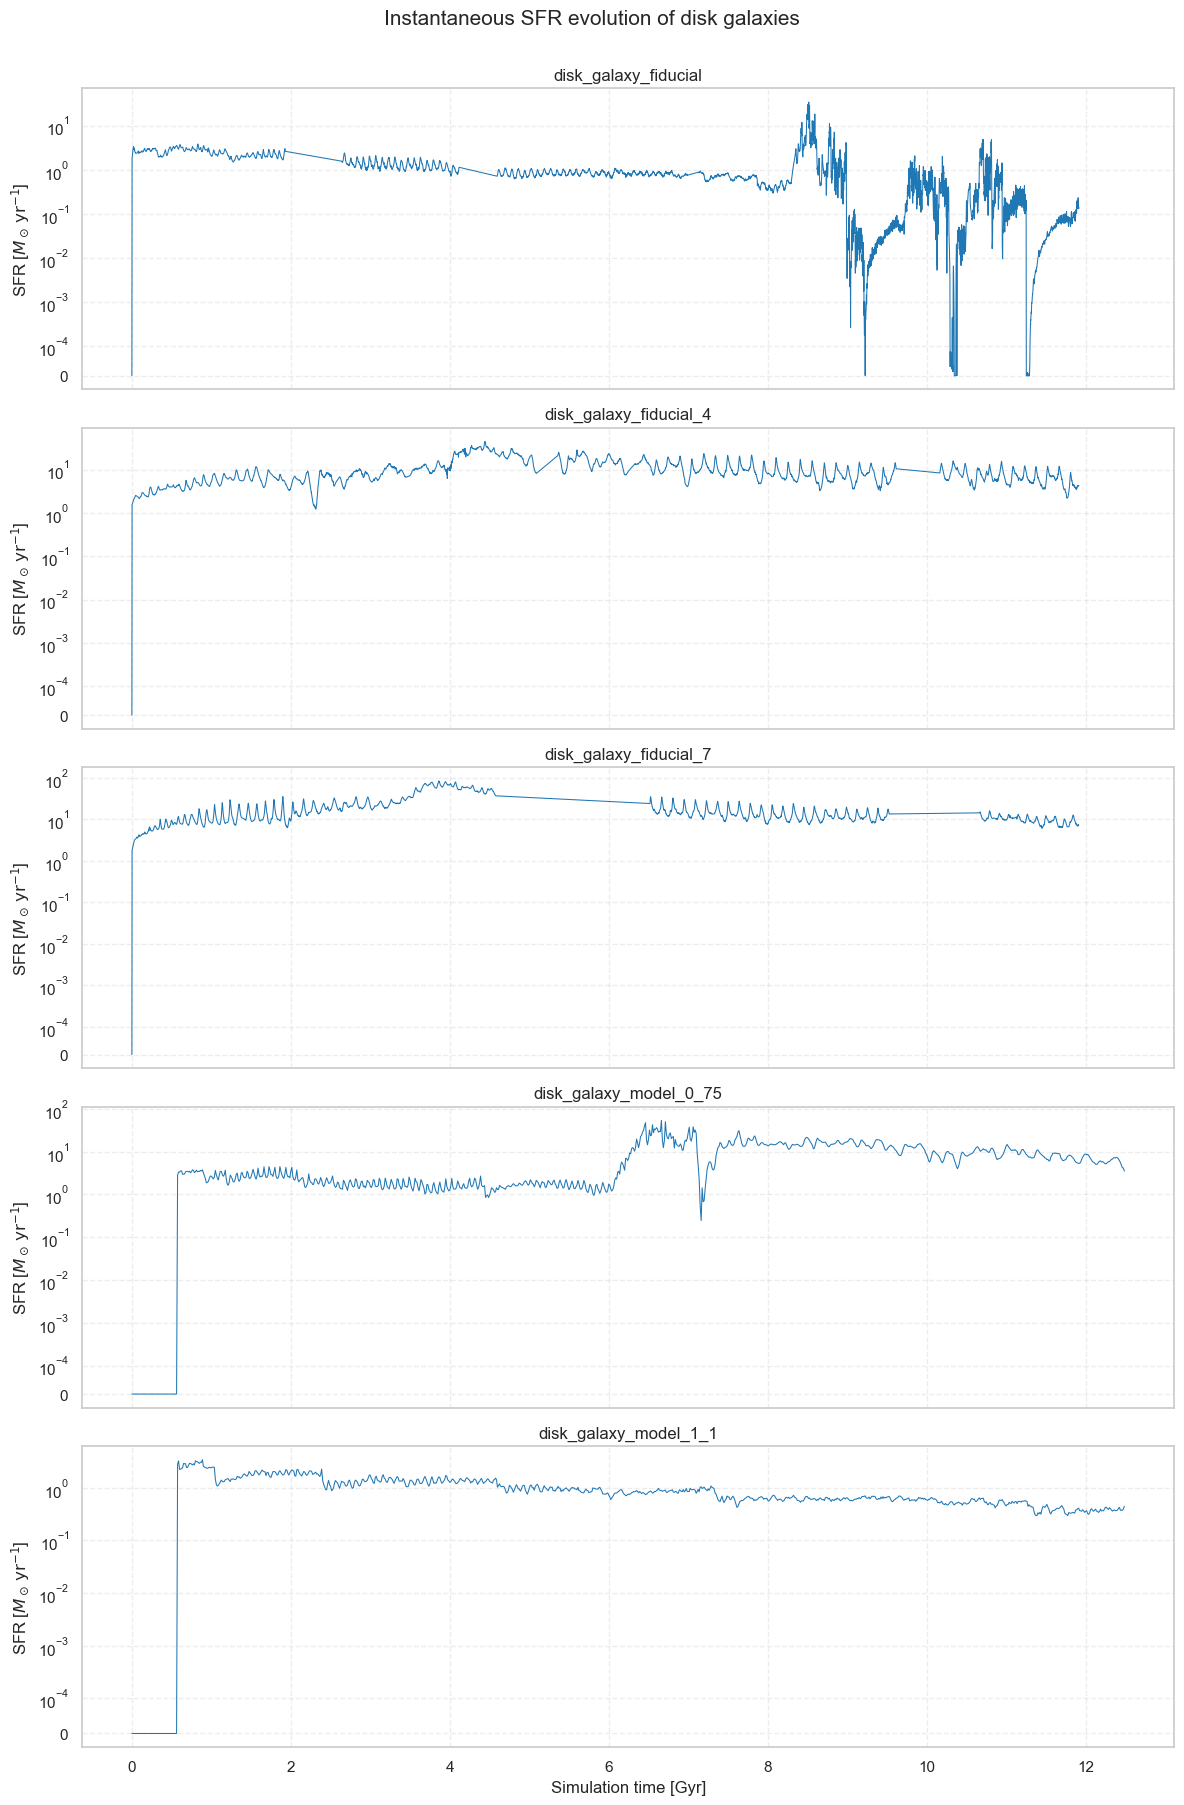

In [6]:
# 单元总注释：以共享时间轴的分面图绘制各盘星系的瞬时 SFR 完整演化。
galaxy_names = sorted(sfr_evolution['galaxy'].unique())
fig, axes = plt.subplots(
    nrows=len(galaxy_names),
    ncols=1,
    figsize=(12, max(3.6 * len(galaxy_names), 4.5)),
    sharex=True,
    squeeze=False,
)

for axis, galaxy_name in zip(axes[:, 0], galaxy_names):
    galaxy_frame = sfr_evolution.loc[sfr_evolution['galaxy'] == galaxy_name]
    axis.plot(
        galaxy_frame['time_gyr'],
        galaxy_frame['sfr_msun_per_yr'],
        linewidth=0.75,
        color='tab:blue',
    )
    axis.set_yscale('symlog', linthresh=SFR_SYMLOG_LINTHRESH, linscale=0.6)
    axis.set_ylabel(r'SFR [$M_\odot\,\mathrm{yr}^{-1}$]')
    axis.set_title(galaxy_name)
    axis.grid(True, which='both', linestyle='--', alpha=0.35)

axes[-1, 0].set_xlabel('Simulation time [Gyr]')
fig.suptitle('Instantaneous SFR evolution of disk galaxies', fontsize=15, y=1.002)
fig.tight_layout()
plt.show()

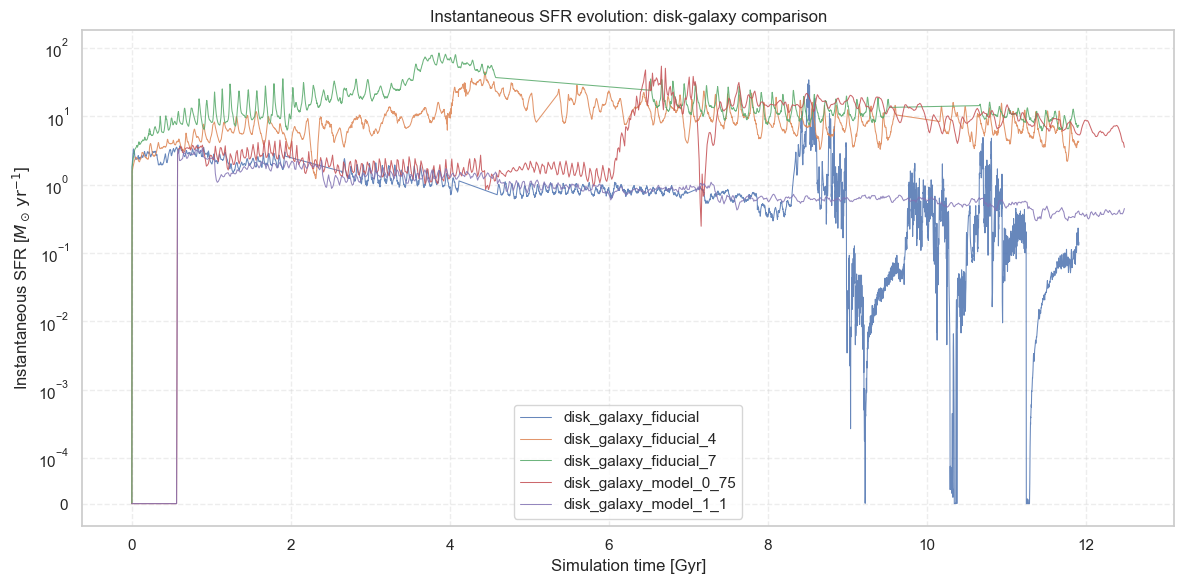

In [7]:
# 单元总注释：把所有可用盘星系叠加到同一坐标系，便于比较瞬时 SFR 的量级和变动。
fig, axis = plt.subplots(figsize=(12, 6))

for galaxy_name, galaxy_frame in sfr_evolution.groupby('galaxy', sort=True):
    axis.plot(
        galaxy_frame['time_gyr'],
        galaxy_frame['sfr_msun_per_yr'],
        linewidth=0.75,
        alpha=0.85,
        label=galaxy_name,
    )

axis.set_yscale('symlog', linthresh=SFR_SYMLOG_LINTHRESH, linscale=0.6)
axis.set_xlabel('Simulation time [Gyr]')
axis.set_ylabel(r'Instantaneous SFR [$M_\odot\,\mathrm{yr}^{-1}$]')
axis.set_title('Instantaneous SFR evolution: disk-galaxy comparison')
axis.grid(True, which='both', linestyle='--', alpha=0.35)
axis.legend(loc='best')
fig.tight_layout()
plt.show()

## 经原始数据核验的五组盘星系 sSFR

以下单元读取本次核验产品 `outputs/ssfr_verified_20261023`，不再扫描原始 snapshot。若内存中已有五组 `sfr_evolution`，按星系和原始文件名匹配、核对 SFR 后复用；否则使用核验时同时保存的原始 SFR。

原始恒星质量定义为 `M_star = sum(Data-Set-14) + sum(Data-Set-12)`，乘质量单位 `2.5e7 Msun`。两者都是每格质量，不再次乘体积。上一版的 `fine 背景恒星密度 × 体积 + 日志 NEWstar(t)` 与该定义逐帧比较。每个运行的最大总质量相对误差不超过0.1%时复用缓存，超过阈值则使用该运行原始质量；逐帧结果及来源保存在 Parquet 与 JSON。

采用模拟输出的背景质量加新恒星质量口径，不额外假设存活恒星质量、质量回收或观测孔径修正。分母不是固定初始质量；`sSFR = SFR / M_star(t)`，单位为 `yr^-1`。

提供五组分面图 `sSFREvolution.png/pdf` 和同轴比较图 `sSFR_comparison.png/pdf`。默认使用模拟绝对时间；设 `SSFR_USE_PRODUCTION_TIME = True` 可减去0.5625 Gyr并排除松弛期。零值保留，缺失帧处断线。需要重新核验时运行 `plot_disk_ssfr_evolution.py --output-dir <新目录>`。

In [ ]:
# 单元总注释：加载原始数据核验结果；这里不读取原始 HDF4 或原始日志。
import json
from pathlib import Path
from IPython.display import display
from VisualScripts.DataAnalysis.plot_disk_ssfr_evolution import (
    DEFAULT_OUTPUT, GALAXIES, plot_evolution,
)
from raw_data_processing.parse_log_file import load_config

SSFR_USE_PRODUCTION_TIME = False
SSFR_OUTPUT_DIR = DEFAULT_OUTPUT
_ssfr_configs = load_config(str(project_root / '.config'))
_verified_path = SSFR_OUTPUT_DIR / 'ssfr_verified.parquet'
_audit_path = SSFR_OUTPUT_DIR / 'stellar_mass_audit.json'
if not _verified_path.is_file() or not _audit_path.is_file():
    raise FileNotFoundError(f'缺少原始质量核验产品：{SSFR_OUTPUT_DIR}')
_ssfr_fingerprint = (_verified_path.stat().st_size, _verified_path.stat().st_mtime_ns)
if globals().get('_ssfr_verified_fingerprint') != _ssfr_fingerprint:
    _ssfr_verified = pd.read_parquet(_verified_path)
    _ssfr_verified_fingerprint = _ssfr_fingerprint
with _audit_path.open(encoding='utf-8') as handle:
    ssfr_mass_audit_report = json.load(handle)
ssfr_mass_audit = pd.DataFrame(ssfr_mass_audit_report['runs'])
display(ssfr_mass_audit[[
    'galaxy', 'n_snapshots', 'max_total_mass_relative_error',
    'max_background_relative_error', 'mass_source',
]])

In [ ]:
# 单元总注释：优先复用内存中的 SFR，按核验时间与质量计算 sSFR。
ssfr_evolution = _ssfr_verified.copy()
_ssfr_names = {f'disk_galaxy_{name}' for name in GALAXIES}
if 'sfr_evolution' in globals():
    _required = {'galaxy', 'snapshot_file', 'sfr_msun_per_yr'}
    if not _required.issubset(sfr_evolution.columns):
        raise ValueError('内存中的 sfr_evolution 缺少星系、文件名或 SFR 列。')
    _input = sfr_evolution.loc[sfr_evolution['galaxy'].isin(_ssfr_names), list(_required)].copy()
    if set(_input['galaxy']) != _ssfr_names:
        raise ValueError('内存中的 sfr_evolution 不含全部五组；请删除该旧变量以使用完整核验表。')
    if _input.duplicated(['galaxy', 'snapshot_file']).any():
        raise ValueError('内存 SFR 中出现重复来源身份。')
    _input = _input.rename(columns={'sfr_msun_per_yr': 'memory_sfr_msun_per_yr'})
    ssfr_evolution = _input.merge(
        _ssfr_verified, on=['galaxy', 'snapshot_file'], how='left',
        validate='one_to_one', indicator=True,
    )
    if not ssfr_evolution['_merge'].eq('both').all():
        raise ValueError('部分内存 SFR 行无法匹配原始质量核验表。')
    if not np.allclose(
        ssfr_evolution['memory_sfr_msun_per_yr'],
        ssfr_evolution['sfr_msun_per_yr'], rtol=1e-6, atol=1e-12,
    ):
        raise ValueError('内存 SFR 与原始 snapshot SFR 不一致，拒绝混合来源。')
    ssfr_evolution['sfr_msun_per_yr'] = ssfr_evolution.pop('memory_sfr_msun_per_yr')
    ssfr_evolution = ssfr_evolution.drop(columns='_merge')
    print('SFR source: existing in-memory sfr_evolution')
else:
    print('SFR source: verified raw SFR saved during the mass audit')
ssfr_evolution['ssfr_per_yr'] = (
    ssfr_evolution['sfr_msun_per_yr'] / ssfr_evolution['stellar_mass_msun']
)
ssfr_evolution = ssfr_evolution.sort_values(['galaxy', 'time_gyr']).reset_index(drop=True)
display(ssfr_evolution.groupby('galaxy').agg(
    n_snapshots=('ssfr_per_yr', 'size'),
    mass_min_msun=('stellar_mass_msun', 'min'),
    mass_max_msun=('stellar_mass_msun', 'max'),
    ssfr_median_per_yr=('ssfr_per_yr', 'median'),
))
# 同时生成两张图；下两个单元分别显示，便于独立查看。
ssfr_fig, ssfr_comparison_fig = plot_evolution(
    ssfr_evolution, _ssfr_configs, SSFR_OUTPUT_DIR, SSFR_USE_PRODUCTION_TIME,
)
plt.close(ssfr_fig)
plt.close(ssfr_comparison_fig)

In [ ]:
# 单元总注释：显示五个星系的 sSFR 分面演化图。
display(ssfr_fig)

In [ ]:
# 单元总注释：显示五个星系的 sSFR 同轴比较图。
display(ssfr_comparison_fig)